# MuVI factor activity per FOV quadrant
This notebook computes the activity of the MuVI factors of `multicellular/MOFACell.ipynb` in the FOV quadrants of the new dataset. It keeps the loadings learned on the TMA dataset and estimates only the factor scores of the new quadrants.

## Approach
1. Refit the MuVI model retained in `MOFACell.ipynb`: 10 factors, no non-negativity, seed 0. The model was not saved, but the refit on the GPU reproduces the exported factor scores exactly. A refit on the CPU gives different factors, so the notebook checks the refit against `data/factor_scores.csv`.
2. Compute the features of `multicellular/PrepareMuData.ipynb` for each quadrant of the new dataset. Each 2048x2048 pixel FOV is split into 4 quadrants of 1024x1024 pixels, the size of a TMA FOV, as in `MistySamplingQuadrants.ipynb`. Cell types are the transferred labels of `AnnotationTransfer.ipynb`, grouped into the 8 coarse classes that serve as MuVI views.
3. Standardise each feature across the new quadrants, as `MOFACell.ipynb` did across the TMA FOVs.
4. Estimate the factor scores of each quadrant from the loadings, using only the features measured in the new dataset.

## Features of the new dataset
The new panel lacks 5 of the markers used as features: `CA9`, `GS`, `ARG1`, `PD1` and `MSH6`. APCs cannot be told apart in the new dataset, and NK cells are rarely found, so the MISTy features that involve them are also missing. The remaining features are computed as in `PrepareMuData.ipynb`:
* the proportion of each coarse cell type among all cells of the quadrant, `Unclear` cells included,
* the median of each metabolic and functional marker in each cell type,
* MISTy interaction importances between cell types, from `MistySamplingQuadrants.ipynb`,
* the mean and standard deviation of the area, perimeter and eccentricity of each cell type.

The section on recovering the factors shows how well the remaining features determine each factor on the TMA FOVs.

## What the scores mean
Each feature is standardised within the new dataset. This removes the shifts in marker intensity between the two panels, but it also means that a score of 0 stands for the average quadrant of the new dataset, not of the TMA dataset. The scores compare quadrants, regions and patients of the new dataset with each other. They cannot be placed on the distributions of the TMA FOVs, for example by stage.

Factors are numbered as in `MOFACell.ipynb`: `Factor k` is MuVI's `factor_{k-1}`.

## Imports

In [1]:
import os
import numpy as np
import pandas as pd
import muon as mu
import muvi
from plotnine import *
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests

/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
data_dir = "./data/"
figure_dir = "./figures/sampling/factor_activity/"
os.makedirs(figure_dir, exist_ok=True)

## Reference MuVI model
### Refit
The same preprocessing and model as the retained model of `MOFACell.ipynb`.

In [3]:
reference = mu.read_h5mu(data_dir + "celltype_features_with_functional_markers.h5mu")
view_names = list(reference.mod.keys())

def standardise(X):
    """Center and scale each feature, ignoring missing values, as in MOFACell.ipynb"""
    X = X - np.nanmean(X, axis=0, keepdims=True)
    return X / np.nanstd(X, axis=0)

for view in view_names:
    reference[view].X = standardise(reference[view].X)

/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/mudata/_core/mudata.py:1531: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/mudata/_core/mudata.py:931: UserWarning: Cannot join columns with the same name because var_names are intersecting.
/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/mudata/_core/mudata.py:1429: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.


In [4]:
# MOFACell.ipynb picks the GPU when one is free; on the CPU the fit gives different factors
device = f"cuda:{muvi.get_free_gpu_idx()}"
model = muvi.tl.from_mdata(reference, n_factors=10, nmf=False, device=device)
model.fit(seed=0)

2026-10-15 16:12:41,839 - muvi.core.models - WARNING - No view names provided!
2026-10-15 16:12:41,839 - muvi.core.models - INFO - Setting the view names to the sorted list of dictonary keys in observations.
2026-10-15 16:12:41,841 - muvi.core.models - INFO - pd.DataFrame detected.
2026-10-15 16:12:41,841 - muvi.core.models - INFO - Storing the index of the view `CD4_lymphocyte` as sample names.
2026-10-15 16:12:41,841 - muvi.core.models - INFO - pd.DataFrame detected.
2026-10-15 16:12:41,842 - muvi.core.models - INFO - pd.DataFrame detected.
2026-10-15 16:12:41,842 - muvi.core.models - INFO - pd.DataFrame detected.
2026-10-15 16:12:41,842 - muvi.core.models - INFO - pd.DataFrame detected.
2026-10-15 16:12:41,842 - muvi.core.models - INFO - pd.DataFrame detected.
2026-10-15 16:12:41,842 - muvi.core.models - INFO - pd.DataFrame detected.
2026-10-15 16:12:41,843 - muvi.core.models - INFO - pd.DataFrame detected.
2026-10-15 16:12:41,843 - muvi.core.models - INFO - pd.DataFrame detected.
2

  0%|                                                                                                                  | 0/10000 [00:00<?, ?it/s]

2026-10-15 16:12:42,140 - root - INFO - Guessed max_plate_nesting = 3


 10%|█████████▌                                                                                   | 1022/10000 [00:45<06:42, 22.31it/s, ELBO=376]

Relative improvement of -0.0007554 < 1e-05 for 10 step(s) in a row, stopping early.
2026-10-15 16:13:27,717 - muvi.core.models - INFO - Call `model._training_log` to inspect the training progress.


In [5]:
factor_names = [f"factor_{i}" for i in range(10)]
factor_labels = {f"factor_{i}": f"Factor {i + 1}" for i in range(10)}

# The refit must reproduce the factor scores exported by MOFACell.ipynb
fitted_scores = model.get_factor_scores(as_df=True)[factor_names]
exported_scores = pd.read_csv(data_dir + "factor_scores.csv").drop(columns="Stage")
exported_scores = exported_scores[[factor_labels[f] for f in factor_names]]
assert np.allclose(fitted_scores.values, exported_scores.values, atol=1e-5), "The refit does not reproduce MOFACell.ipynb"
print("Largest difference to the exported scores:", np.abs(fitted_scores.values - exported_scores.values).max())

Largest difference to the exported scores: 4.440892098500626e-16


### Parameters used for the projection
In MuVI, the features of a sample are its factor scores times the loadings, plus Gaussian noise with a standard deviation per feature. The factor scores have a standard normal prior, and each view's likelihood is weighted by a view scale. With the loadings, noise levels and view scales fixed, the most likely factor scores of a new sample have a closed form.

In [6]:
loadings = model.get_factor_loadings(as_df=True)  # view -> factors x features
loadings = {view: loadings[view].loc[factor_names] for view in view_names}
noise_sd = dict(zip(model.view_names, [s[0] for s in model._guide.get_sigma(as_list=True)]))
view_scales = dict(zip(model.view_names, model._model.view_scales))

# MuVI centers each view again and sets its global standard deviation to 1
def muvi_normalise(X):
    X = X - np.nanmean(X, axis=0, keepdims=True)
    return X / np.nanstd(X)

reference_observations = model.get_observations(as_df=True)  # view -> samples x features
for view in view_names:
    assert np.allclose(muvi_normalise(reference[view].X), reference_observations[view].values, atol=1e-5, equal_nan=True)  # MuVI stores float32

In [7]:
def project(observations, features_used=None):
    """Posterior mean of the factor scores of each sample, with the loadings fixed.

    observations: view -> DataFrame of samples x features, normalised like the MuVI input.
    Missing values are skipped, and so are features not in features_used (view -> list of names).
    """
    samples = next(iter(observations.values())).index
    scores = np.zeros((len(samples), len(factor_names)))
    for i in range(len(samples)):
        precision = np.eye(len(factor_names))
        weighted = np.zeros(len(factor_names))
        for view in view_names:
            y = observations[view].iloc[i]
            observed = y.notna().values
            if features_used is not None:
                observed &= y.index.isin(features_used[view])
            w = loadings[view].loc[:, y.index[observed]].values
            inverse_variance = view_scales[view] / pd.Series(noise_sd[view], index=loadings[view].columns)[y.index[observed]].values ** 2
            precision += (w * inverse_variance) @ w.T
            weighted += (w * inverse_variance) @ y.values[observed]
        scores[i] = np.linalg.solve(precision, weighted)
    return pd.DataFrame(scores, index=samples, columns=factor_names)

In [8]:
# Loadings and noise levels of the reference model, for later use
loading_table = pd.concat({view: loadings[view].T.assign(noise_sd=noise_sd[view], view_scale=view_scales[view])
                           for view in view_names}, names=["view", "feature"])
loading_table.rename(columns=factor_labels).to_csv(data_dir + "sampling/muvi_reference_loadings.csv")

## Features of the new quadrants
### Cells and quadrants
The quadrant table of `MistySamplingQuadrants.ipynb` holds the transformed cell table with the transferred labels. Quadrants with 20 cancer cells or fewer are excluded, as in `PrepareMuData.ipynb` and `MistySamplingQuadrants.ipynb`.

In [9]:
cell_table = pd.read_csv(data_dir + "sampling/cell_table_transformed_quadrants.csv")

# Coarse classes of PrepareMuData.ipynb, the views of the MuVI model
types_of_interest = dict(
    Other_immune_cell = ["APC", "B_cell", "Neutrophil", "Other_immune_cell"],
    Fibroblast = ["CAF"],
    Macrophage = ["CD163_Macrophage", "CD68_Macrophage"],
    CD4_lymphocyte = ["CD4_Tcell", "T_reg_cell"],
    Epithelial_cell = ["Cancer_cell"],
    Endothelial_cell = ["Endothelial_cell"],
    Monocyte = ["Monocyte"],
    Cytotoxic_lymphocyte = ["NK_cell", "CD8_Tcell"],
)
assert set(types_of_interest) == set(view_names)
type_to_view = {t: view for view, types in types_of_interest.items() for t in types}
cell_table["view"] = cell_table["annotation_consensus"].map(type_to_view)  # NaN for Unclear cells

n_cancer = (cell_table["annotation_consensus"] == "Cancer_cell").groupby(cell_table["fov_quadrant"]).sum()
kept_quadrants = n_cancer.index[n_cancer > 20]
print(f"Quadrants kept: {len(kept_quadrants)} of {len(n_cancer)}")
cell_table = cell_table[cell_table["fov_quadrant"].isin(kept_quadrants)]

quadrants = (cell_table.groupby("fov_quadrant")[["fov", "patient", "region", "quadrant"]].first()
             .loc[sorted(kept_quadrants)])
quadrants.groupby("region").agg(quadrants=("fov", "size"), fovs=("fov", "nunique"), patients=("patient", "nunique"))

Quadrants kept: 525 of 624


,quadrants,fovs,patients
region,,,
IM,223,76,26
TC,302,78,26


### Features as in `PrepareMuData.ipynb`

In [10]:
metab_markers = ['CA9', 'CD98', 'CytC', 'MCT1', 'ASCT2', 'LDH', 'GS', 'GLS', 'ATP5A', 'CS', 'PKM2', 'GLUT1', 'ARG1', 'CPT1A', 'Ki67']
functional_markers = ["PD1", "PDL1", "STING1", "MSH2", "MSH6"]
morpho_features = ["eccentricity", "perimeter", "area"]
markers_in_new_panel = [m for m in metab_markers + functional_markers if m in cell_table.columns]
print("Markers missing in the new panel:", [m for m in metab_markers + functional_markers if m not in cell_table.columns])

misty_features = pd.read_csv(data_dir + "sampling/misty_quadrant_celltype_features.csv", index_col="sample")
assert set(misty_features.index) == set(quadrants.index)

def quadrant_features(view):
    """Features of one view per quadrant, in the column order of the reference, NaN where not measured"""
    view_cells = cell_table[cell_table["view"] == view].groupby("fov_quadrant")
    columns = {}
    columns["proportion"] = (cell_table["view"] == view).groupby(cell_table["fov_quadrant"]).mean()
    columns.update(view_cells[markers_in_new_panel].median().to_dict("series"))
    columns.update(view_cells[morpho_features].mean().to_dict("series"))
    columns.update(view_cells[morpho_features].std().add_suffix("_std").to_dict("series"))
    columns.update(misty_features.to_dict("series"))
    features = pd.DataFrame(columns).reindex(quadrants.index)
    return features.reindex(columns=reference[view].var_names)

new_features = {view: quadrant_features(view) for view in view_names}

Markers missing in the new panel: ['CA9', 'GS', 'ARG1', 'PD1', 'MSH6']


A feature counts as available if it was measured in the new dataset and varies across quadrants. Missing values remain where a cell type is absent from a quadrant, as in the TMA features.

In [11]:
available_features = {view: [f for f in X.columns if X[f].notna().any() and X[f].std() > 0]
                      for view, X in new_features.items()}
pd.DataFrame({
    "reference features": {view: reference[view].n_vars for view in view_names},
    "available": {view: len(available_features[view]) for view in view_names},
    "missing": {view: ", ".join(f for f in reference[view].var_names if f not in available_features[view]) for view in view_names},
})

,reference features,available,missing
Other_immune_cell,40,33,"CA9, GS, ARG1, juxtaview.40_l.APC_APC, paravie..."
Fibroblast,40,36,"CA9, GS, ARG1, MSH6"
Macrophage,39,35,"CA9, GS, ARG1, MSH6"
CD4_lymphocyte,33,28,"CA9, GS, ARG1, PD1, MSH6"
Epithelial_cell,49,42,"CA9, GS, ARG1, juxtaview.40_l.Cancer_cell_NK_c..."
Endothelial_cell,38,34,"CA9, GS, ARG1, MSH6"
Monocyte,38,33,"CA9, GS, ARG1, juxtaview.40_l.Monocyte_APC, MSH6"
Cytotoxic_lymphocyte,31,24,"CA9, GS, ARG1, juxtaview.40_l.NK_cell_NK_cell,..."


In [12]:
# Fraction of quadrants without each cell type, where the marker and morphology features are missing
pd.Series({view: (X["proportion"] == 0).mean() for view, X in new_features.items()}, name="quadrants without the cell type").round(3)

Other_immune_cell       0.002
Fibroblast              0.004
Macrophage              0.019
CD4_lymphocyte          0.030
Epithelial_cell         0.000
Endothelial_cell        0.004
Monocyte                0.006
Cytotoxic_lymphocyte    0.013
Name: quadrants without the cell type, dtype: float64

## Recovering the factors from the available features
Before projecting the new quadrants, the same projection is applied to the TMA FOVs. With all features, it should reproduce the fitted factor scores. With only the features available in the new dataset, the correlation with the fitted scores shows how well these features determine each factor.

In [13]:
recovery = pd.DataFrame({
    "all features": project(reference_observations).corrwith(fitted_scores),
    "features available in the new dataset": project(reference_observations, available_features).corrwith(fitted_scores),
}).rename(index=factor_labels)
recovery.round(3)

,all features,features available in the new dataset
Factor 1,0.999,0.992
Factor 2,0.999,0.980
Factor 3,1.000,0.945
Factor 4,0.999,0.993
Factor 5,1.000,0.986
Factor 6,0.999,0.989
Factor 7,1.000,0.981
Factor 8,0.999,0.992
Factor 9,1.000,0.987
Factor 10,1.000,0.982


In [14]:
# Share of each factor's squared loadings carried by the features missing in the new dataset
squared = pd.concat({view: loadings[view] ** 2 for view in view_names}, axis=1)
is_missing = [f not in available_features[view] for view, f in squared.columns]
(squared.loc[:, is_missing].sum(axis=1) / squared.sum(axis=1)).rename(index=factor_labels).rename("share of squared loadings missing").round(2)

Factor 1     0.14
Factor 2     0.22
Factor 3     0.17
Factor 4     0.14
Factor 5     0.21
Factor 6     0.11
Factor 7     0.28
Factor 8     0.15
Factor 9     0.16
Factor 10    0.23
Name: share of squared loadings missing, dtype: float64

With all features, the projection reproduces the fitted scores, with correlations of at least 0.999. With only the features available in the new dataset, the correlations range from 0.945 for Factor 3 to 0.993 for Factor 4, although the missing features carry 11 to 28% of the squared loadings of each factor. The remaining features determine every factor well.

## Factor activity in the new quadrants
Each feature is standardised across the new quadrants, then normalised per view as MuVI does, and projected onto the loadings.

In [15]:
new_observations = {
    view: pd.DataFrame(muvi_normalise(standardise(new_features[view][available_features[view]].values)),
                       index=quadrants.index, columns=available_features[view])
    for view in view_names
}
new_scores = project(new_observations).rename(columns=factor_labels)
factor_order = [factor_labels[f] for f in factor_names]

n_observed = sum(new_observations[view].notna().sum(axis=1) for view in view_names)
print(f"Features per quadrant: median {n_observed.median():.0f}, minimum {n_observed.min()}, of {sum(len(f) for f in available_features.values())} available")
new_scores.describe().round(2)

Features per quadrant: median 265, minimum 162, of 265 available


,Factor 1,Factor 2,Factor 3,Factor 4,Factor 5,Factor 6,Factor 7,Factor 8,Factor 9,Factor 10
count,525.00,525.00,525.00,525.00,525.00,525.00,525.00,525.00,525.00,525.00
mean,-0.00,-0.01,0.00,0.00,0.00,0.00,-0.01,-0.00,0.00,0.01
std,0.58,0.54,0.62,0.53,0.46,0.54,0.54,0.56,0.69,0.49
min,-2.02,-1.19,-1.28,-1.81,-1.01,-1.62,-1.90,-1.29,-1.40,-1.02
25%,-0.37,-0.43,-0.40,-0.33,-0.33,-0.36,-0.32,-0.39,-0.49,-0.33
50%,0.02,-0.03,-0.07,-0.02,-0.03,-0.05,0.05,-0.06,-0.06,-0.02
75%,0.39,0.33,0.32,0.34,0.29,0.29,0.37,0.32,0.46,0.26
max,2.02,1.69,2.84,1.58,2.23,2.11,1.61,2.71,2.39,2.33


### Tumor core and invasive margin
Each patient contributes quadrants from both regions. Quadrant scores are first averaged per patient and region, so patients with more FOVs do not weigh more, and the regions are compared with a Wilcoxon signed-rank test across patients. P-values are corrected across the 10 factors with the Benjamini-Hochberg FDR, which governs the claims, and with Bonferroni for reference. The table also counts the patients whose invasive margin scores higher than their tumor core.

The two regions are different tissue: the invasive margin holds more immune cells and stroma than the tumor core, so factors driven by cell composition are expected to differ. Duplicate FOVs, named `..._duplicate1`, are kept as in `MistySamplingQuadrants.ipynb`.

In [16]:
scores_long = new_scores.join(quadrants).melt(id_vars=list(quadrants.columns), var_name="factor", value_name="score")
per_patient = scores_long.groupby(["factor", "patient", "region"])["score"].mean().unstack("region")

region_tests = []
for factor in factor_order:
    paired = per_patient.loc[factor].dropna()
    difference = paired["IM"] - paired["TC"]
    region_tests.append({
        "factor": factor,
        "patients": len(paired),
        "mean IM - TC": difference.mean(),
        "patients with IM > TC": int((difference > 0).sum()),
        "p": wilcoxon(paired["IM"], paired["TC"]).pvalue,
    })
region_tests = pd.DataFrame(region_tests).set_index("factor")
region_tests["q (FDR)"] = multipletests(region_tests["p"], method="fdr_bh")[1]
region_tests["p (Bonferroni)"] = multipletests(region_tests["p"], method="bonferroni")[1]
region_tests.round(4)

,patients,mean IM - TC,patients with IM > TC,p,q (FDR),p (Bonferroni)
factor,,,,,,
Factor 1,26,0.2679,19,0.0073,0.0122,0.0729
Factor 2,26,0.2660,19,0.0016,0.0040,0.0160
Factor 3,26,0.3650,21,0.0000,0.0002,0.0003
Factor 4,26,0.3284,22,0.0000,0.0002,0.0004
Factor 5,26,0.0295,15,0.3533,0.3533,1.0000
Factor 6,26,-0.2870,4,0.0005,0.0016,0.0047
Factor 7,26,-0.0960,8,0.2079,0.2309,1.0000
Factor 8,26,0.1932,19,0.0130,0.0185,0.1295
Factor 9,26,0.2629,20,0.0061,0.0122,0.0613


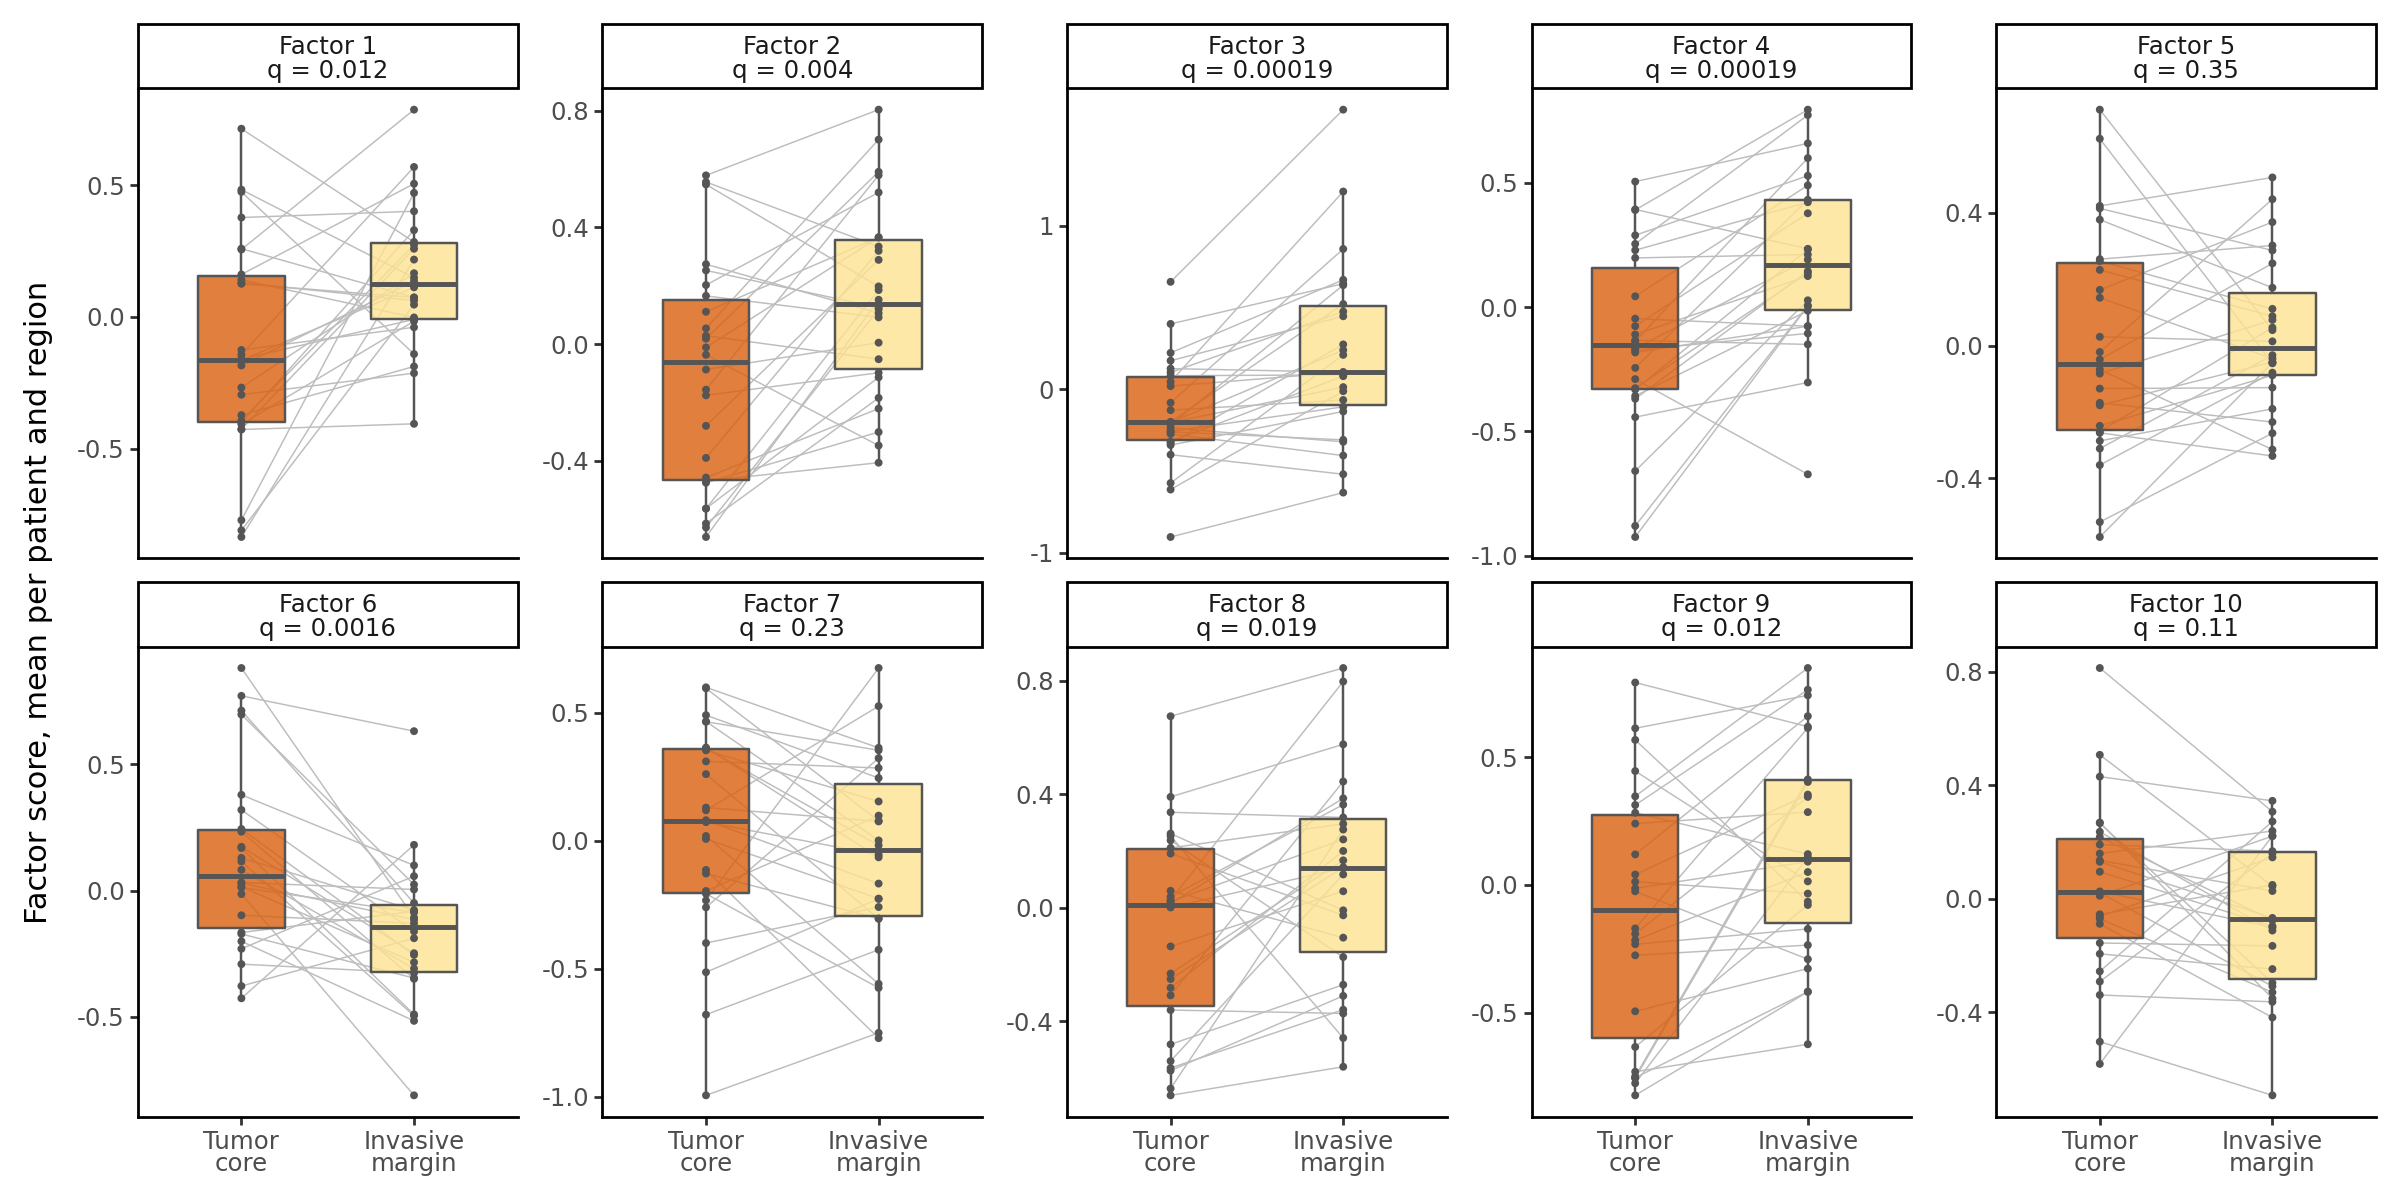

In [17]:
plot_df = per_patient.stack().rename("score").reset_index()
facet_names = {f: f"{f}\nq = {region_tests.loc[f, 'q (FDR)']:.2g}" for f in factor_order}
plot_df["factor"] = pd.Categorical(plot_df["factor"].map(facet_names), categories=[facet_names[f] for f in factor_order])
plot_df["region"] = pd.Categorical(plot_df["region"].map({"TC": "Tumor\ncore", "IM": "Invasive\nmargin"}),
                                   categories=["Tumor\ncore", "Invasive\nmargin"])

# Region colors of AnnotationTransfer.ipynb
region_colors = {"Tumor\ncore": "#d95f0e", "Invasive\nmargin": "#fee391"}
gp = (
    ggplot(plot_df, aes(x="region", y="score"))
    + geom_line(aes(group="patient"), color="#bdbdbd", size=0.3)
    + geom_boxplot(aes(fill="region"), outlier_shape="", width=0.5, color="#555555", alpha=0.8)
    + geom_point(color="#555555", size=0.6)
    + facet_wrap("~factor", ncol=5, scales="free_y")
    + scale_fill_manual(values=region_colors)
    + guides(fill="none")
    + theme_classic()
    + theme(figure_size=(12, 6))
    + labs(x="", y="Factor score, mean per patient and region")
)
ggsave(gp, figure_dir + "factor_scores_tc_vs_im.pdf", width=12, height=6, verbose=False)
gp

Seven factors differ between the regions at an FDR of 5%. Factors 1, 2, 3, 4, 8 and 9 are higher at the invasive margin, in 19 to 22 of the 26 patients. Factor 6 is lower: only 4 patients have a higher score at the invasive margin. Factors 2, 3, 4 and 6 also pass the Bonferroni correction. Factors 5, 7 and 10 show no difference between the regions.

### Where the variation lies
Quadrants are nested in FOVs, FOVs in regions and regions in patients. For each factor, the sum of squares of the quadrant scores is split into these levels. A large share within FOVs means the 4 quadrants of a FOV often differ, so a single TMA-sized core would not represent its FOV well.

In [18]:
def nested_shares(scores):
    """Share of the sum of squares between patients, between regions of a patient, between FOVs of a region, and between quadrants of a FOV"""
    df = scores.to_frame("score").join(quadrants)
    means = {level: df.groupby(keys)["score"].transform("mean")
             for level, keys in [("patient", ["patient"]), ("region", ["patient", "region"]), ("fov", ["fov"])]}
    total = ((df["score"] - df["score"].mean()) ** 2).sum()
    return pd.Series({
        "between patients": ((means["patient"] - df["score"].mean()) ** 2).sum() / total,
        "between regions of a patient": ((means["region"] - means["patient"]) ** 2).sum() / total,
        "between FOVs of a region": ((means["fov"] - means["region"]) ** 2).sum() / total,
        "between quadrants of a FOV": ((df["score"] - means["fov"]) ** 2).sum() / total,
    })

variance_shares = pd.DataFrame({f: nested_shares(new_scores[f]) for f in factor_order}).T
variance_shares.round(2)

,between patients,between regions of a patient,between FOVs of a region,between quadrants of a FOV
Factor 1,0.22,0.21,0.26,0.31
Factor 2,0.31,0.16,0.23,0.30
Factor 3,0.36,0.17,0.17,0.29
Factor 4,0.34,0.19,0.27,0.21
Factor 5,0.29,0.09,0.21,0.41
Factor 6,0.25,0.18,0.32,0.26
Factor 7,0.36,0.13,0.25,0.25
Factor 8,0.31,0.13,0.25,0.31
Factor 9,0.34,0.13,0.35,0.17
Factor 10,0.22,0.12,0.29,0.37


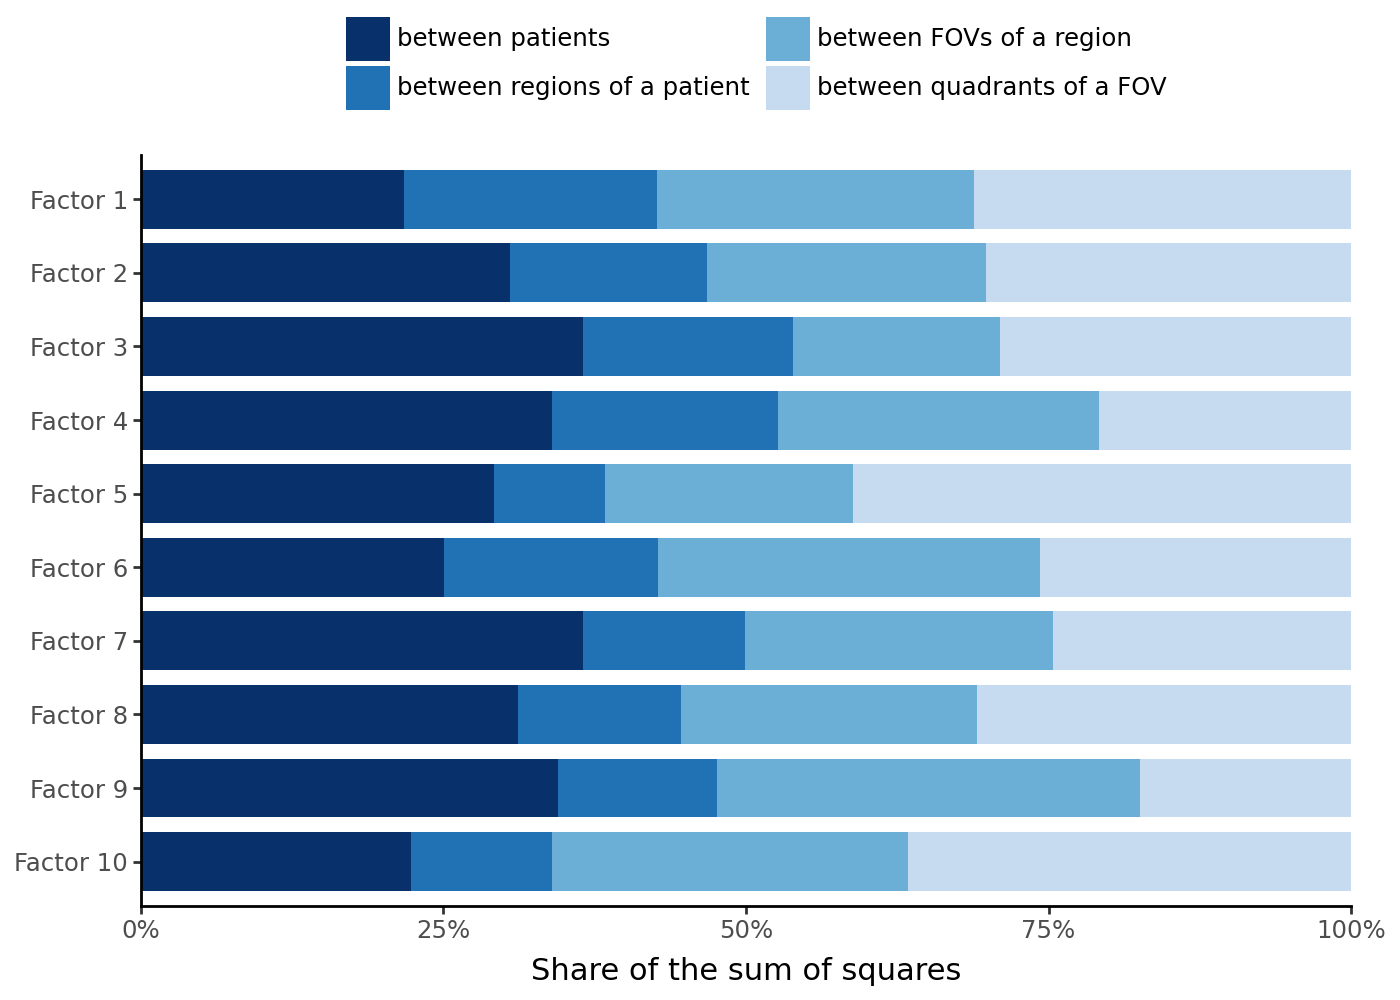

In [19]:
share_df = variance_shares.rename_axis("factor").reset_index().melt(id_vars="factor", var_name="level", value_name="share")
share_df["factor"] = pd.Categorical(share_df["factor"], categories=factor_order[::-1])
share_df["level"] = pd.Categorical(share_df["level"], categories=list(variance_shares.columns)[::-1])

gp = (
    ggplot(share_df, aes(x="factor", y="share", fill="level"))
    + geom_col(width=0.8)
    + coord_flip()
    + scale_fill_manual(values=dict(zip(variance_shares.columns, ["#08306b", "#2171b5", "#6baed6", "#c6dbef"])))
    + guides(fill=guide_legend(reverse=True, nrow=2))
    + scale_y_continuous(labels=lambda breaks: [f"{b:.0%}" for b in breaks], expand=(0, 0))
    + theme_classic()
    + theme(legend_position="top", figure_size=(7, 5))
    + labs(x="", y="Share of the sum of squares", fill="")
)
ggsave(gp, figure_dir + "factor_score_variance_levels.pdf", width=7, height=5, verbose=False)
gp

Differences between patients account for 22 to 36% of the sum of squares, and differences between the two regions of a patient for another 9 to 21%. The 4 quadrants of a FOV account for 17 to 41%, about as much as the differences between patients. Some of this may be noise from features computed on few cells, such as the markers of a rare cell type in a quadrant. It also means that a single TMA-sized core gives a noisy estimate of the factor activity of the tissue around it.

## Export

In [20]:
export = quadrants.join(new_scores).join(n_observed.rename("n_features_observed"))
export.rename_axis("fov_quadrant").to_csv(data_dir + "sampling/muvi_factor_scores_quadrants.csv")

# Unstandardised features of the new quadrants, with the views and feature names of the reference
features_mdata = mu.MuData({view: mu.AnnData(X) for view, X in new_features.items()})
features_mdata.obs = features_mdata.obs.join(quadrants)
features_mdata.write_h5mu(data_dir + "sampling/celltype_features_quadrants.h5mu")

/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/mudata/_core/mudata.py:1531: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/mudata/_core/mudata.py:931: UserWarning: Cannot join columns with the same name because var_names are intersecting.
/home/loan/miniforge3/envs/liana/lib/python3.11/site-packages/mudata/_core/mudata.py:1429: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
... storing 'fov' as categorical
... storing 'patient'